# L2_T5 — Add a "None of These" Class and Adapt to Phone Photos
### Layer 2 of the Aura pipeline · Task 5

**Why this notebook exists.** L2_T4 showed the T3 baseline (a) is barely better than guessing on phone photos
(52.0% vs a 50.0% majority baseline) and (b) labels **95%** of unrelated conditions as acne or pigmentation, with
*higher* confidence than on real cases, so a confidence threshold cannot protect users.

**What this notebook does:**
1. Adds a 4th class, **`none_of_these`**, trained on SCIN's other-disease cases (eczema, urticaria, insect bites...).
2. Adapts the model to phone photos by training on DermNet **plus** SCIN.
3. Measures the result with **5-fold cross-validation on SCIN cases**, so every SCIN case is scored by a model that
   never trained on it. Out-of-fold results are compared directly to the T4 baseline.
4. Trains a final model on everything and exports TFLite.

**What this can and cannot prove, stated before you see any numbers:**
- Only **~100 in-scope SCIN cases** exist (pigmentation has about 10). Results are directional, with wide intervals.
  Subgroups under 30 cases are flagged **unreliable**.
- The negatives are **other diseases, not healthy skin**. A model that learns "eczema is not acne" can still
  mislabel a clear-skin face. A real clear-skin test needs your own consented selfies.
- SCIN is US-based; "Asian" is not Filipino. Skin-tone fairness for Filipino users is **still unmeasured**.
- The final model is trained on all data, so it has **no held-out score of its own**. The cross-validated numbers are
  the performance claim.

**Data rules:** SCIN images are used for training and evaluation here, under the SCIN Data Use License (attribution,
note of modification, **no re-identification**). Images stay on this runtime's local disk and are **not** saved to
Drive; only per-case results are saved. If the runtime resets, SCIN re-downloads (large, ~12 GB).

**Run order:** Runtime → GPU (T4). Expect roughly 30-45 minutes total. Run cells top to bottom.

## Step 0 — Mount Drive and confirm prior tasks

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, json, time, shutil, tarfile

DRIVE_ROOT = "/content/drive/MyDrive/Projects/Aura/Layer2_SkinCondition"
MANIFEST_PATH = f"{DRIVE_ROOT}/manifest.json"
with open(MANIFEST_PATH) as f:
    manifest = json.load(f)
for k in ("preprocessing", "model_training", "selfie_gap_eval"):
    assert k in manifest, f"manifest missing '{k}' -- did that task finish?"

DRIVE_MODEL_DIR = f"{DRIVE_ROOT}/models"
DRIVE_EVAL_DIR = f"{DRIVE_ROOT}/evaluation"
T3_KERAS = f"{DRIVE_MODEL_DIR}/aura_l2_condition_baseline.keras"
T3_LABELS = f"{DRIVE_MODEL_DIR}/aura_l2_condition_labels.json"
T4_RESULTS = f"{DRIVE_EVAL_DIR}/scin_eval_results.csv"
PP_ARCHIVE = manifest["preprocessing"]["drive_archive"]
for p in (T3_KERAS, T3_LABELS, T4_RESULTS, PP_ARCHIVE):
    assert os.path.exists(p), f"Missing {p}"

COND_CLASSES = json.load(open(T3_LABELS))["classes"]       # 3 condition classes, T3 order
CLASSES = COND_CLASSES + ["none_of_these"]                  # index 3 = none_of_these
NONE_IDX = len(COND_CLASSES)
print("4-class label order:", CLASSES)
print(f"T4 baseline on SCIN: accuracy {manifest['selfie_gap_eval']['scin_accuracy']:.3f}")

LOCAL_ROOT = "/content/aura_local/Layer2_SkinCondition"
LOCAL_MODEL = f"{LOCAL_ROOT}/models_t5"
for d in (LOCAL_ROOT, LOCAL_MODEL):
    os.makedirs(d, exist_ok=True)


Mounted at /content/drive
4-class label order: ['acne', 'pigmentation', 'redness_sensitivity', 'none_of_these']
T4 baseline on SCIN: accuracy 0.520


## Step 1 — License notice and dependencies

In [ ]:
notice = """# Data provenance notice (L2_T5)

Sources:
- DermNet (L2_T1/T2), research use; the mirror states no license.
- SCIN (Skin Condition Image Network) -- https://huggingface.co/datasets/google/scin
  License: SCIN Data Use License. Citation: Ward et al., JAMA Netw Open 2024, doi:10.1001/jamanetworkopen.2024.46615

Use in this project: SCIN images are used to TRAIN and cross-validate the L2_T5 model.
Obligations: keep attribution; state that images were modified (face-crop / resize / CLAHE);
never attempt to re-identify or re-link contributors.
Stored on Drive: per-case results and model files only. No SCIN images are stored.
"""
open(f"{DRIVE_EVAL_DIR}/DATA_PROVENANCE_L2_T5.md", "w").write(notice)
print("✅ Provenance notice written.")


✅ Provenance notice written.


In [ ]:
!pip -q install datasets mediapipe opencv-python-headless pillow pandas scikit-learn tqdm seaborn
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 14.7 MB/s eta 0:00:00
TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Load DermNet (the source domain), with the T3 cleaning and leakage-aware validation fold
Same drops as T3 (skin cancers, `pigmented bands`, `nevus comedonicus`). One grouped fold is held back as the
DermNet validation set used for early stopping.

In [ ]:
local_arch = f"{LOCAL_ROOT}/dermnet_conditions_preprocessed.tar.gz"
shutil.copy2(PP_ARCHIVE, local_arch)
DN_ROOT = f"{LOCAL_ROOT}/dn_data"
shutil.rmtree(DN_ROOT, ignore_errors=True); os.makedirs(DN_ROOT)
with tarfile.open(local_arch, "r:gz") as tar:
    tar.extractall(DN_ROOT, filter="data")
DN_DIR = f"{DN_ROOT}/dermnet_conditions_preprocessed"

dn = pd.read_csv(f"{DN_DIR}/processed_labels.csv")
DROP = ["basal cell", "carcinoma", "keratosis", "nevus comedonicus", "pigmented bands"]
dn = dn[~dn["label_norm"].apply(lambda l: any(k in l for k in DROP))].reset_index(drop=True)
dn["path"] = DN_DIR + "/" + dn["processed_filename"]
dn["y"] = dn["aura_condition"].map({c: i for i, c in enumerate(COND_CLASSES)})
assert dn["y"].notna().all()
dn["y"] = dn["y"].astype(int)
print("DermNet after cleaning:", len(dn)); print(dn["aura_condition"].value_counts().to_string())

from PIL import Image
def dhash(path, size=8):
    im = Image.open(path).convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(im, dtype=np.int16); return (a[:, 1:] > a[:, :-1]).flatten()
H = np.stack([dhash(p) for p in dn["path"]])
parent = list(range(len(dn)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for i in range(len(dn)):
    for j in np.where((H[i + 1:] != H[i]).sum(1) <= 6)[0] + i + 1:
        ri, rj = find(i), find(j)
        if ri != rj: parent[rj] = ri
dn["group"] = [find(i) for i in range(len(dn))]

from sklearn.model_selection import StratifiedGroupKFold
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(dn, dn["y"], dn["group"]))
dn_val = dn.iloc[folds[1][1]]
dn_train = dn.drop(dn_val.index)
assert not (set(dn_train.group) & set(dn_val.group))
print(f"DermNet train {len(dn_train)} / val {len(dn_val)} (no duplicate group spans both)")


DermNet after cleaning: 900
aura_condition
acne                   368
redness_sensitivity    311
pigmentation           221
DermNet train 720 / val 180 (no duplicate group spans both)


## Step 3 — Load SCIN and build the 4-class case table
Same mapping idea as L2_T4, with extra exclusions found in its review: venous-stasis **hemosiderin** staining,
**exogenous** pigmentation and **acne urticata** are not cosmetic acne/pigmentation, so they become `none_of_these`.
**Review the printed condition names.**

In [ ]:
from datasets import load_dataset
import ast, json as _json
scin = load_dataset("google/scin", split="train")
IMAGE_COLS = [c for c in ("image_1_path", "image_2_path", "image_3_path") if c in scin.column_names]
meta = scin.select_columns([c for c in scin.column_names if c not in IMAGE_COLS]).to_pandas()
meta["dataset_index"] = np.arange(len(meta))
meta["case_id"] = meta["case_id"].astype(str)

CATEGORY_RULES = {
    "acne": {"include": ["acne", "comedo"], "exclude": ["keloidalis", "scar", "histology", "rosacea", "nevus comedonicus", "urticata"]},
    "redness_sensitivity": {"include": ["rosacea", "perioral"], "exclude": ["rhinophyma", "histology"]},
    "pigmentation": {"include": ["lentigo", "sun damaged", "melasma", "freckle", "pigment", "hyperpig", "ephelid"],
                     "exclude": ["maligna", "melanoma", "melanocytic", "nevi", "nevus", "incontinentia", "purpuric", "histology",
                                 "hypopigment", "depigment", "vitiligo", "basal cell", "carcinoma", "keratosis",
                                 "hemosiderin", "venous", "exogenous"]},
}
def map_condition(name):
    n = str(name).strip().lower()
    for cat, rule in CATEGORY_RULES.items():
        if any(k in n for k in rule["include"]) and not any(k in n for k in rule["exclude"]):
            return cat
    return None

def parse_weights(row):
    v = row.get("weighted_skin_condition_label")
    if isinstance(v, dict) and v: return {str(k): float(w) for k, w in v.items()}
    if isinstance(v, str) and v.strip():
        for loader in (_json.loads, ast.literal_eval):
            try:
                d = loader(v)
                if isinstance(d, dict) and d: return {str(k): float(w) for k, w in d.items()}
            except Exception: pass
    v = row.get("dermatologist_skin_condition_on_label_name")
    names = None
    if isinstance(v, (list, tuple, np.ndarray)): names = [str(x) for x in v]
    elif isinstance(v, str) and v.strip():
        for loader in (_json.loads, ast.literal_eval):
            try:
                d = loader(v)
                if isinstance(d, (list, tuple)): names = [str(x) for x in d]; break
            except Exception: pass
        if names is None: names = [v]
    return {n: 1.0 / len(names) for n in names} if names else {}

meta["weights"] = meta.apply(parse_weights, axis=1)
assert meta["weights"].apply(bool).sum() > 500, "Labels did not parse -- see L2_T4 Step 3 sample values."

def classify(w):
    if not w: return ("unlabeled", None, None)
    top, tw = max(w.items(), key=lambda kv: kv[1])
    if tw < 0.5: return ("ambiguous", None, top)
    cat = map_condition(top)
    return ("in_scope", cat, top) if cat else ("out_of_scope", "none_of_these", top)

r = meta["weights"].apply(classify)
meta["scope"] = [x[0] for x in r]; meta["true_cat"] = [x[1] for x in r]; meta["top_condition"] = [x[2] for x in r]

def parse_fst(v):
    if isinstance(v, str) and v.startswith("FST") and v[3:].isdigit():
        n = int(v[3:]); return n if 1 <= n <= 6 else None
def derm_fst(row):
    labs = [parse_fst(row.get(f"dermatologist_fitzpatrick_skin_type_label_{i}")) for i in (1, 2, 3)]
    labs = [l for l in labs if l is not None]
    return None if (not labs or max(labs) - min(labs) > 1) else int(np.floor(np.median(labs) + 0.5))
def is_yes(v): return v is True or (isinstance(v, str) and v.strip().upper() in ("YES", "TRUE"))
meta["fst"] = meta.apply(derm_fst, axis=1)
meta["fst_group"] = pd.cut(meta["fst"], bins=[0, 2, 4, 6], labels=["FST I-II", "FST III-IV", "FST V-VI"])
meta["is_asian"] = meta["race_ethnicity_asian"].map(is_yes) if "race_ethnicity_asian" in meta else False
meta["head_neck"] = meta["body_parts_head_or_neck"].map(is_yes) if "body_parts_head_or_neck" in meta else False

pool = meta[meta.scope.isin(["in_scope", "out_of_scope"])].copy().reset_index(drop=True)
pool["y"] = pool["true_cat"].map({c: i for i, c in enumerate(CLASSES)}).astype(int)
print(pool["true_cat"].value_counts().to_string())
print("\nCondition names mapped to each category (CHECK THESE):")
for cat in COND_CLASSES:
    print(f"\n[{cat}]"); print(pool[pool.true_cat == cat]["top_condition"].value_counts().to_string())
print("\nTop 15 none_of_these conditions:"); print(pool[pool.true_cat == "none_of_these"]["top_condition"].value_counts().head(15).to_string())
MIN_PER_CLASS = 5
assert pool[pool.y < NONE_IDX]["y"].value_counts().min() >= MIN_PER_CLASS, "A condition class has under 5 cases -- cannot cross-validate."


README.md:   0%|          | 0.00/24.5k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

Some datasets params were ignored: ['splits', 'download_size', 'dataset_size']. Make sure to use only valid params for the dataset builder and to have a up-to-date version of the `datasets` library.


Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

data/train-00000-of-00026.parquet: reconstructing file:   0%|          |  0.00B /  493MB            

...

data/train-00025-of-00026.parquet: reconstructing file:   0%|          |  0.00B /  487MB            

data/train-00025-of-00026.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5033 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/19 [00:00<?, ?it/s]

true_cat
none_of_these          2126
acne                     50
redness_sensitivity      38
pigmentation             10

Condition names mapped to each category (CHECK THESE):

[acne]
top_condition
Acne    50

[pigmentation]
top_condition
Post-Inflammatory hyperpigmentation    6
Melasma                                3
Hyperpigmentation                      1

[redness_sensitivity]
top_condition
Rosacea                25
Perioral Dermatitis    13

Top 15 none_of_these conditions:
top_condition
Eczema                         373
Allergic Contact Dermatitis    232
Urticaria                      182
Insect Bite                    144
Folliculitis                   101
Psoriasis                       65
Tinea                           61
Herpes Zoster                   54
Herpes Simplex                  51
Pigmented purpuric eruption     45
Acute dermatitis, NOS           37
Impetigo                        37
Pityriasis rosea                34
Irritant Contact Dermatitis     33
Tinea Vers

## Step 4 — Preprocess SCIN images to local disk (same pipeline as T2/T3/T4)
In-scope cases use all their images; `none_of_these` cases use their first image only, to keep runtime down.

In [ ]:
import cv2, urllib.request
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision
from tqdm.auto import tqdm

IMG = 224
fd_path = f"{LOCAL_ROOT}/blaze_face_short_range.tflite"
if not os.path.exists(fd_path):
    urllib.request.urlretrieve("https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite", fd_path)
detector = mp_vision.FaceDetector.create_from_options(
    mp_vision.FaceDetectorOptions(base_options=mp_python.BaseOptions(model_asset_path=fd_path)))

def preprocess_to_uint8(img_rgb, margin=0.25):
    h, w = img_rgb.shape[:2]
    res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(img_rgb)))
    found, crop = bool(res.detections), img_rgb
    if found:
        b = res.detections[0].bounding_box
        mx, my = int(b.width * margin), int(b.height * margin)
        x1, y1 = max(0, b.origin_x - mx), max(0, b.origin_y - my)
        x2, y2 = min(w, b.origin_x + b.width + mx), min(h, b.origin_y + b.height + my)
        if x2 > x1 and y2 > y1: crop = img_rgb[y1:y2, x1:x2]
    out = cv2.resize(crop, (IMG, IMG), interpolation=cv2.INTER_AREA)
    l, a, bb = cv2.split(cv2.cvtColor(out, cv2.COLOR_RGB2LAB))
    return cv2.cvtColor(cv2.merge([cv2.createCLAHE(2.0, (8, 8)).apply(l), a, bb]), cv2.COLOR_LAB2RGB), found

SC_DIR = f"{LOCAL_ROOT}/scin_pp"; os.makedirs(SC_DIR, exist_ok=True)
img_rows = []
for r in tqdm(pool.itertuples(index=False), total=len(pool), desc="SCIN cases"):
    rec = scin[int(r.dataset_index)]
    k_used = 0
    for k in IMAGE_COLS:
        im = rec.get(k)
        if im is None: continue
        if r.y == NONE_IDX and k_used >= 1: break
        path = f"{SC_DIR}/{r.case_id}_{k_used}.jpg"
        if not os.path.exists(path):
            out, found = preprocess_to_uint8(np.array(im.convert("RGB")))
            cv2.imwrite(path, cv2.cvtColor(out, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 92])
        else:
            found = None
        img_rows.append({"case_id": r.case_id, "path": path, "y": int(r.y)})
        k_used += 1
sc_imgs = pd.DataFrame(img_rows)
print(f"SCIN images prepared: {len(sc_imgs)} from {sc_imgs.case_id.nunique()} cases")


SCIN cases:   0%|          | 0/2224 [00:00<?, ?it/s]

SCIN images prepared: 2327 from 2224 cases


## Step 5 — Training machinery
- Backbone starts from the **T3 model** (trained on DermNet only, never on SCIN, so no SCIN leakage into CV).
- New 4-way head. Stage 1 trains the head; Stage 2 unfreezes the top 30 layers (BatchNorm frozen) at a low rate.
- In-scope SCIN images are repeated ×3 in training; `none_of_these` training cases are capped per condition so eczema
  doesn't dominate. Class weights are balanced on what remains. No hue/saturation augmentation (colour is the signal).

In [ ]:
BATCH, AUTOTUNE = 32, tf.data.AUTOTUNE
SCIN_INSCOPE_REPEAT = 3
NEG_CAP_PER_CONDITION = 20
EPOCHS1, EPOCHS2 = 6, 8

def _load(path, y):
    img = tf.image.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.cast(tf.image.resize(img, (IMG, IMG)), tf.float32), y
augment = keras.Sequential([
    layers.RandomFlip("horizontal"), layers.RandomRotation(0.08), layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2, value_range=(0, 255)), layers.RandomContrast(0.2)])

def make_ds(paths, ys, train):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), np.asarray(ys, dtype="int32")))
    if train: ds = ds.shuffle(len(paths), seed=1)
    ds = ds.map(_load, num_parallel_calls=AUTOTUNE)
    if train: ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

local_t3 = f"{LOCAL_ROOT}/t3.keras"; shutil.copy2(T3_KERAS, local_t3)

def build_model():
    t3 = keras.models.load_model(local_t3)
    base = next(l for l in t3.layers if isinstance(l, keras.Model))
    inp = keras.Input((IMG, IMG, 3))
    x = layers.GlobalAveragePooling2D()(base(inp, training=False))
    out = layers.Dense(len(CLASSES), activation="softmax")(layers.Dropout(0.3)(x))
    return keras.Model(inp, out), base

def scin_training_rows(case_ids, seed):
    d = sc_imgs[sc_imgs.case_id.isin(case_ids)].copy()
    cond = pool.set_index("case_id")["top_condition"]
    d["cond"] = d["case_id"].map(cond)
    pos = d[d.y < NONE_IDX]
    pos = pd.concat([pos] * SCIN_INSCOPE_REPEAT)
    neg = d[d.y == NONE_IDX]
    neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=seed))
    return pd.concat([pos, neg])[["path", "y"]]

from sklearn.utils.class_weight import compute_class_weight
def train_one(train_df, val_df, seed=0, verbose=0):
    keras.utils.set_random_seed(seed)
    model, base = build_model()
    cw_arr = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=train_df["y"].values)
    cw = {i: float(w) for i, w in enumerate(cw_arr)}
    tr, va = make_ds(train_df.path, train_df.y, True), make_ds(val_df.path, val_df.y, False)
    es = lambda: keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor="val_loss")
    base.trainable = False
    model.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(tr, validation_data=va, epochs=EPOCHS1, class_weight=cw, callbacks=[es()], verbose=verbose)
    base.trainable = True
    for l in base.layers[:-30]: l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization): l.trainable = False
    model.compile(keras.optimizers.Adam(1e-5), "sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(tr, validation_data=va, epochs=EPOCHS2, class_weight=cw, callbacks=[es()], verbose=verbose)
    return model
print("Training machinery ready.")


Training machinery ready.


## Step 6 — 5-fold cross-validation on SCIN cases
Each fold: train on DermNet + the training-fold SCIN cases; score the held-out SCIN cases. Case-level prediction =
mean softmax over the case's images. A small slice of the training SCIN cases is kept for early stopping.

In [ ]:
from sklearn.model_selection import StratifiedKFold, train_test_split
skf = StratifiedKFold(5, shuffle=True, random_state=42)
case_tbl = pool[["case_id", "y"]].reset_index(drop=True)

oof = []
for fold, (tr_i, te_i) in enumerate(skf.split(case_tbl, case_tbl["y"]), 1):
    t0 = time.time()
    tr_cases, te_cases = case_tbl.iloc[tr_i], case_tbl.iloc[te_i]
    fit_cases, es_cases = train_test_split(tr_cases, test_size=0.12, stratify=tr_cases["y"], random_state=fold)
    train_df = pd.concat([dn_train[["path", "y"]], scin_training_rows(set(fit_cases.case_id), fold)])
    val_df = pd.concat([dn_val[["path", "y"]], scin_training_rows(set(es_cases.case_id), fold)])
    model = train_one(train_df, val_df, seed=fold)

    te_imgs = sc_imgs[sc_imgs.case_id.isin(set(te_cases.case_id))].reset_index(drop=True)
    P = model.predict(make_ds(te_imgs.path, te_imgs.y, False), verbose=0)
    probs = pd.DataFrame(P, columns=CLASSES); probs["case_id"] = te_imgs["case_id"]
    cp = probs.groupby("case_id")[CLASSES].mean().reset_index(); cp["fold"] = fold
    oof.append(cp)
    print(f"fold {fold}/5: train imgs {len(train_df)}, test cases {len(te_cases)}, {(time.time()-t0)/60:.1f} min")
    keras.backend.clear_session()

oof = pd.concat(oof, ignore_index=True)
res = pool.merge(oof, on="case_id", how="inner")
Pm = res[CLASSES].values
res["pred_cat"] = [CLASSES[i] for i in Pm.argmax(1)]
res["confidence"] = Pm.max(1)
assert len(res) == len(pool), f"Missing out-of-fold predictions: {len(res)} of {len(pool)}"
print("\n✅ Every SCIN case has an out-of-fold prediction.")


/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=seed))
/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=s

fold 1/5: train imgs 1878, test cases 445, 6.7 min


/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=seed))
/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=s

fold 2/5: train imgs 1903, test cases 445, 8.1 min


/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=seed))
/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=s

fold 3/5: train imgs 1877, test cases 445, 8.5 min


/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=seed))
/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=s

fold 4/5: train imgs 1896, test cases 445, 7.7 min


/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=seed))
/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=s

fold 5/5: train imgs 1923, test cases 444, 8.5 min

✅ Every SCIN case has an out-of-fold prediction.


## Step 7 — Results: before (T4 baseline) vs after (T5, cross-validated)

IN-SCOPE cases: 98 | majority-class baseline 0.510
  T4 baseline accuracy (same cases):        0.510
  T5 cross-validated accuracy:              0.459  (95% CI 0.367-0.561)
  ...of in-scope cases wrongly called 'none_of_these': 0.255

OUT-OF-SCOPE cases: 2126
  T4 baseline correctly rejected:            0.000  (it had no way to say 'none')
  T5 correctly rejected as none_of_these:   0.928  (95% CI 0.917-0.939)
  T5 still labelled as a condition (false alarm): 0.072

Balanced score (mean of in-scope accuracy and out-of-scope rejection): 0.693

                      precision    recall  f1-score   support

               acne      0.182     0.400     0.250        50
       pigmentation      0.000     0.000     0.000        10
redness_sensitivity      0.298     0.658     0.410        38
      none_of_these      0.987     0.928     0.957      2126

           accuracy                          0.907      2224
          macro avg      0.367     0.496     0.404      2224
       weighted avg  

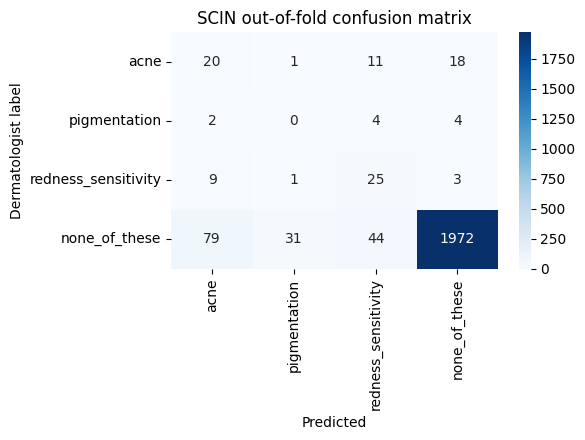

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt, seaborn as sns
rng = np.random.default_rng(0)
MIN_N = 30

ins = res[res.y < NONE_IDX].copy()
oos = res[res.y == NONE_IDX].copy()
ins["correct"] = ins["true_cat"] == ins["pred_cat"]
oos["rejected"] = oos["pred_cat"] == "none_of_these"

def boot_ci(x, n=1000):
    x = np.asarray(x, dtype=float)
    b = [x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)]
    return np.percentile(b, [2.5, 97.5])

# T4 baseline restricted to the same in-scope cases (T5 excludes a few cases T4 counted as in-scope)
t4 = pd.read_csv(T4_RESULTS); t4["case_id"] = t4["case_id"].astype(str)
t4i = t4[t4.case_id.isin(set(ins.case_id))].merge(ins[["case_id", "true_cat"]], on="case_id", suffixes=("_t4", ""))
t4_acc = float((t4i["pred_cat"] == t4i["true_cat"]).mean())

maj = ins["true_cat"].value_counts(normalize=True).max()
lo, hi = boot_ci(ins.correct)
print(f"IN-SCOPE cases: {len(ins)} | majority-class baseline {maj:.3f}")
print(f"  T4 baseline accuracy (same cases):        {t4_acc:.3f}")
print(f"  T5 cross-validated accuracy:              {ins.correct.mean():.3f}  (95% CI {lo:.3f}-{hi:.3f})")
print(f"  ...of in-scope cases wrongly called 'none_of_these': {(ins.pred_cat == 'none_of_these').mean():.3f}")
rlo, rhi = boot_ci(oos.rejected)
print(f"\nOUT-OF-SCOPE cases: {len(oos)}")
print(f"  T4 baseline correctly rejected:            0.000  (it had no way to say 'none')")
print(f"  T5 correctly rejected as none_of_these:   {oos.rejected.mean():.3f}  (95% CI {rlo:.3f}-{rhi:.3f})")
print(f"  T5 still labelled as a condition (false alarm): {1 - oos.rejected.mean():.3f}")
bal = (ins.correct.mean() + oos.rejected.mean()) / 2
print(f"\nBalanced score (mean of in-scope accuracy and out-of-scope rejection): {bal:.3f}")

print("\n", classification_report(res["true_cat"], res["pred_cat"], labels=CLASSES, digits=3, zero_division=0))
cm = confusion_matrix(res["true_cat"], res["pred_cat"], labels=CLASSES)
plt.figure(figsize=(6, 4.5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("Dermatologist label"); plt.title("SCIN out-of-fold confusion matrix"); plt.tight_layout(); plt.show()


## Step 8 — Subgroups: skin tone, head/neck, face detected
Two rates per group: **in-scope accuracy** (small n) and **none_of_these rejection** (large n, so skin-tone fairness of the
false-alarm rate *is* measurable even though in-scope fairness is not). Only quote rows marked `OK`.

In [ ]:
def row(name, mi, mo):
    di, do = ins[mi], oos[mo]
    out = {"subgroup": name, "n_in": len(di), "n_out": len(do)}
    out["inscope_acc"] = round(float(di.correct.mean()), 3) if len(di) else None
    out["inscope_reliable"] = "OK" if len(di) >= MIN_N else "UNRELIABLE (n<30)"
    out["oos_rejection"] = round(float(do.rejected.mean()), 3) if len(do) else None
    out["oos_reliable"] = "OK" if len(do) >= MIN_N else "UNRELIABLE (n<30)"
    return out

T = lambda d: np.ones(len(d), dtype=bool)
rows = [row("All", T(ins), T(oos))]
for g in ["FST I-II", "FST III-IV", "FST V-VI"]:
    rows.append(row(g, (ins.fst_group == g).values, (oos.fst_group == g).values))
rows.append(row("Asian-flagged", ins.is_asian.values, oos.is_asian.values))
rows.append(row("Head/neck (selfie proxy)", ins.head_neck.values, oos.head_neck.values))
rows.append(row("Not head/neck", (~ins.head_neck).values, (~oos.head_neck).values))
sg = pd.DataFrame(rows); print(sg.to_string(index=False))

print("\nPer-condition in-scope recall (n shown; pigmentation is expected to be unreliable):")
for c in COND_CLASSES:
    d = ins[ins.true_cat == c]
    print(f"  {c:22s} n={len(d):3d}  recall={d.correct.mean():.3f}  {'OK' if len(d) >= MIN_N else 'UNRELIABLE (n<30)'}")


                subgroup  n_in  n_out  inscope_acc  inscope_reliable  oos_rejection oos_reliable
                     All    98   2126        0.459                OK          0.928           OK
                FST I-II    43    799        0.581                OK          0.920           OK
              FST III-IV    40    965        0.450                OK          0.938           OK
                FST V-VI    12    176        0.083 UNRELIABLE (n<30)          0.898           OK
           Asian-flagged     4     38        0.750 UNRELIABLE (n<30)          0.921           OK
Head/neck (selfie proxy)    54    247        0.444                OK          0.713           OK
           Not head/neck    44   1879        0.477                OK          0.956           OK

Per-condition in-scope recall (n shown; pigmentation is expected to be unreliable):
  acne                   n= 50  recall=0.400  OK
  pigmentation           n= 10  recall=0.000  UNRELIABLE (n<30)
  redness_sensitivity    n

## Step 9 — Does confidence now help? (answer only when a condition is predicted with confidence ≥ threshold)
In T4, confidence was *higher* on unrelated conditions, so no threshold worked. Compare.

In [ ]:
rows = []
for t in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    ans_i = ins[(ins.pred_cat != "none_of_these") & (ins.confidence >= t)]
    ans_o = oos[(oos.pred_cat != "none_of_these") & (oos.confidence >= t)]
    rows.append({"threshold": t,
                 "in_scope_answered_correctly": round(float(ans_i.correct.sum()) / len(ins), 3),
                 "in_scope_accuracy_when_answering": round(float(ans_i.correct.mean()), 3) if len(ans_i) else None,
                 "out_of_scope_false_alarm": round(len(ans_o) / len(oos), 3)})
thr = pd.DataFrame(rows); print(thr.to_string(index=False))
print(f"\nMedian confidence  in-scope: {ins.confidence.median():.3f}   out-of-scope: {oos.confidence.median():.3f}")


 threshold  in_scope_answered_correctly  in_scope_accuracy_when_answering  out_of_scope_false_alarm
       0.0                        0.459                             0.616                     0.072
       0.5                        0.388                             0.717                     0.050
       0.6                        0.276                             0.711                     0.028
       0.7                        0.184                             0.783                     0.014
       0.8                        0.143                             0.875                     0.008
       0.9                        0.041                             1.000                     0.002

Median confidence  in-scope: 0.639   out-of-scope: 0.943


## Step 10 — Informational readiness gate
Project targets, not clinical standards. Check the **right-hand column**, not just PASS/FAIL.

In [ ]:
def status(v): return "PASS" if v is True else ("FAIL" if v is False else "UNKNOWN")
rel = sg.set_index("subgroup")
gate = []
gate.append(("Out-of-scope rejection >= 0.85", bool(oos.rejected.mean() >= 0.85), f"{oos.rejected.mean():.3f}"))
gate.append(("In-scope accuracy >= 0.70", bool(ins.correct.mean() >= 0.70), f"{ins.correct.mean():.3f}"))
gate.append(("In-scope called 'none' <= 0.15", bool((ins.pred_cat == 'none_of_these').mean() <= 0.15), f"{(ins.pred_cat == 'none_of_these').mean():.3f}"))
if rel.loc["FST V-VI", "oos_reliable"] == "OK" and rel.loc["FST I-II", "oos_reliable"] == "OK":
    gap = float(rel.loc["FST I-II", "oos_rejection"] - rel.loc["FST V-VI", "oos_rejection"])
    gate.append(("Rejection gap FST I-II minus V-VI <= 0.10", bool(abs(gap) <= 0.10), f"{gap:+.3f}"))
else:
    gate.append(("Rejection gap FST I-II minus V-VI <= 0.10", None, "n<30"))
if rel.loc["FST V-VI", "inscope_reliable"] == "OK" and rel.loc["FST I-II", "inscope_reliable"] == "OK":
    g2 = float(rel.loc["FST I-II", "inscope_acc"] - rel.loc["FST V-VI", "inscope_acc"])
    gate.append(("In-scope accuracy gap FST I-II minus V-VI <= 0.10", bool(abs(g2) <= 0.10), f"{g2:+.3f}"))
else:
    gate.append(("In-scope accuracy gap FST I-II minus V-VI <= 0.10", None, "FST V-VI in-scope n<30 -- cannot assess"))
for n, ok, v in gate: print(f"  {status(ok):8s} {n}  [{v}]")


  PASS     Out-of-scope rejection >= 0.85  [0.928]
  FAIL     In-scope accuracy >= 0.70  [0.459]
  FAIL     In-scope called 'none' <= 0.15  [0.255]
  PASS     Rejection gap FST I-II minus V-VI <= 0.10  [+0.022]
  UNKNOWN  In-scope accuracy gap FST I-II minus V-VI <= 0.10  [FST V-VI in-scope n<30 -- cannot assess]


## Step 11 — Train the final model on everything and export
Uses all DermNet and all SCIN cases (10% of SCIN cases held back only for early stopping). **It has no held-out
score.** The cross-validated numbers above are the performance claim for this recipe.

In [ ]:
fit_c, es_c = train_test_split(case_tbl, test_size=0.10, stratify=case_tbl["y"], random_state=7)
final_train = pd.concat([dn_train[["path", "y"]], scin_training_rows(set(fit_c.case_id), 7)])
final_val = pd.concat([dn_val[["path", "y"]], scin_training_rows(set(es_c.case_id), 7)])
final_model = train_one(final_train, final_val, seed=7, verbose=2)

KERAS_OUT = f"{LOCAL_MODEL}/aura_l2_condition_v2_none.keras"
TFLITE_OUT = f"{LOCAL_MODEL}/aura_l2_condition_v2_none.tflite"
LABELS_OUT = f"{LOCAL_MODEL}/aura_l2_condition_v2_none_labels.json"
final_model.save(KERAS_OUT)
conv = tf.lite.TFLiteConverter.from_keras_model(final_model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
open(TFLITE_OUT, "wb").write(conv.convert())
json.dump({"classes": CLASSES, "input_size": IMG, "input_range": "0-255 float32 RGB", "output": "softmax over 4 classes",
           "note": "none_of_these = other conditions seen in SCIN, NOT confirmed healthy skin. Research model, not for users."},
          open(LABELS_OUT, "w"), indent=2)

try:
    from ai_edge_litert.interpreter import Interpreter
except Exception:
    Interpreter = tf.lite.Interpreter
it = Interpreter(model_path=TFLITE_OUT); it.allocate_tensors()
i_d, o_d = it.get_input_details()[0], it.get_output_details()[0]
smp = sc_imgs.sample(40, random_state=1); agree = 0
for p in smp.path:
    x = tf.cast(tf.image.decode_jpeg(tf.io.read_file(p), channels=3), tf.float32).numpy()[None]
    it.set_tensor(i_d["index"], x.astype("float32")); it.invoke()
    agree += int(it.get_tensor(o_d["index"])[0].argmax() == final_model.predict(x, verbose=0)[0].argmax())
print(f"TFLite size {os.path.getsize(TFLITE_OUT)/1e6:.1f} MB | TFLite vs Keras agreement {agree}/40")


/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=seed))
/tmp/ipykernel_655/2176672473.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  neg = neg.groupby("cond", group_keys=False).apply(lambda g: g.sample(min(len(g), NEG_CAP_PER_CONDITION), random_state=s

Epoch 1/6
67/67 - 72s - 1s/step - accuracy: 0.5049 - loss: 1.1669 - val_accuracy: 0.7534 - val_loss: 0.6819
Epoch 2/6
67/67 - 24s - 355ms/step - accuracy: 0.6923 - loss: 0.8474 - val_accuracy: 0.7831 - val_loss: 0.5948
Epoch 3/6
67/67 - 25s - 368ms/step - accuracy: 0.7107 - loss: 0.7880 - val_accuracy: 0.7808 - val_loss: 0.5583
Epoch 4/6
67/67 - 40s - 598ms/step - accuracy: 0.7426 - loss: 0.7181 - val_accuracy: 0.7854 - val_loss: 0.5365
Epoch 5/6
67/67 - 25s - 379ms/step - accuracy: 0.7468 - loss: 0.6906 - val_accuracy: 0.8037 - val_loss: 0.5198
Epoch 6/6
67/67 - 41s - 607ms/step - accuracy: 0.7694 - loss: 0.6435 - val_accuracy: 0.8037 - val_loss: 0.5200
Epoch 1/8
67/67 - 76s - 1s/step - accuracy: 0.7698 - loss: 0.6626 - val_accuracy: 0.7968 - val_loss: 0.5173
Epoch 2/8
67/67 - 25s - 373ms/step - accuracy: 0.7755 - loss: 0.6352 - val_accuracy: 0.8059 - val_loss: 0.5056
Epoch 3/8
67/67 - 41s - 617ms/step - accuracy: 0.7788 - loss: 0.6107 - val_accuracy: 0.8037 - val_loss: 0.5056
Epoch 4

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite size 4.6 MB | TFLite vs Keras agreement 39/40


## Step 12 — Save to Drive (models + per-case results, no images) and verify after remount

In [ ]:
out_cols = ["case_id", "top_condition", "true_cat", "pred_cat", "confidence", "fold", "fst", "fst_group", "is_asian", "head_neck"] + CLASSES
p_res = f"{LOCAL_ROOT}/scin_cv_results_t5.csv"; res[out_cols].to_csv(p_res, index=False)
p_sg = f"{LOCAL_ROOT}/scin_cv_subgroups_t5.csv"; sg.to_csv(p_sg, index=False)
p_thr = f"{LOCAL_ROOT}/scin_cv_abstention_t5.csv"; thr.to_csv(p_thr, index=False)

targets = {p_res: DRIVE_EVAL_DIR, p_sg: DRIVE_EVAL_DIR, p_thr: DRIVE_EVAL_DIR,
           KERAS_OUT: DRIVE_MODEL_DIR, TFLITE_OUT: DRIVE_MODEL_DIR, LABELS_OUT: DRIVE_MODEL_DIR}
for src, dstdir in targets.items():
    dst = f"{dstdir}/{os.path.basename(src)}"
    shutil.copy2(src, dst); time.sleep(1)
    assert os.path.getsize(dst) == os.path.getsize(src), f"SIZE MISMATCH {src}"
drive.flush_and_unmount(); time.sleep(3); drive.mount('/content/drive')
for src, dstdir in targets.items():
    dst = f"{dstdir}/{os.path.basename(src)}"
    assert os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(src), f"MISSING AFTER REMOUNT {dst}"
    print("  ✅", os.path.basename(dst), f"{os.path.getsize(dst)/1e6:.2f} MB")


## Step 13 — Update the manifest (written last)

In [ ]:
manifest["none_class_v2"] = {
    "generated_at_utc": pd.Timestamp.utcnow().isoformat(),
    "recipe": "T3 backbone + 4-way head; DermNet + SCIN training; 5-fold CV on SCIN cases",
    "classes": CLASSES,
    "in_scope_cases": int(len(ins)), "out_of_scope_cases": int(len(oos)),
    "cv_inscope_accuracy": round(float(ins.correct.mean()), 4),
    "cv_inscope_accuracy_ci95": [round(float(lo), 4), round(float(hi), 4)],
    "t4_baseline_accuracy_same_cases": round(t4_acc, 4),
    "majority_baseline": round(float(maj), 4),
    "cv_oos_rejection": round(float(oos.rejected.mean()), 4),
    "cv_oos_rejection_ci95": [round(float(rlo), 4), round(float(rhi), 4)],
    "inscope_called_none": round(float((ins.pred_cat == "none_of_these").mean()), 4),
    "balanced_score": round(float(bal), 4),
    "subgroups": sg.to_dict(orient="records"),
    "abstention_table": thr.to_dict(orient="records"),
    "readiness_gate": [{"check": n, "result": status(ok), "value": v} for n, ok, v in gate],
    "final_model_tflite": f"{DRIVE_MODEL_DIR}/aura_l2_condition_v2_none.tflite",
    "caveats": [
        "Only ~100 in-scope SCIN cases; pigmentation about 10. Directional only.",
        "none_of_these = other diseases, not healthy skin. Clear-skin behaviour untested.",
        "SCIN is US-based; no Filipino evaluation. Skin-tone fairness for in-scope classes not assessable.",
        "Final model has no held-out score; cross-validated numbers are the performance claim.",
        "Not for end users.",
    ],
}
with open(MANIFEST_PATH, "w") as f:
    json.dump(manifest, f, indent=2, default=str)
print(json.dumps({k: manifest["none_class_v2"][k] for k in
      ["cv_inscope_accuracy", "t4_baseline_accuracy_same_cases", "cv_oos_rejection", "inscope_called_none", "balanced_score", "readiness_gate"]}, indent=2))


## Done — what to do next
1. Read Step 7 (before/after), then Step 8's `oos_rejection` by skin tone, then Step 9.
2. Only quote rows marked `OK`.
3. Ask for the **task summary cell** and paste it here as the last markdown cell.

**What T5 cannot settle (needs your own data):** whether the model works on **clear-skin selfies**, on **Filipino skin
tones**, and on **Fitzpatrick V-VI in-scope conditions**. That is the data-collection work in the roadmap.